# Derivatives of function hooks

Goal: the derivative of a hook where the solver uses one, a point-implicit friction: JAX AD by default, the user's partials, or zero.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import zoomy_core.model.initial_conditions as IC
from zoomy_core.mesh import LSQMesh
from zoomy_core.misc.misc import ZArray
from zoomy_core.model.boundary_conditions import BoundaryConditions, FromModel
from zoomy_core.model.models import SWE
from zoomy_core.numerics import NumericalSystemModel
from zoomy_core.numerics.numerical_system_model import SourceTreatment
from zoomy_core.symsolver.hooks import HookDerivative, HookFunction, hook
from zoomy_core.systemmodel.system_model import SystemModel
from zoomy_jax.symsolver.solver import SymbolicHyperbolicSolverJax

In [2]:
class SWEManningHook(SWE):
    def source(self):
        return ZArray([[0], [0], [hook("manning")(self.Q.h, self.Q.hu)]])

In [3]:
def manning(h, hu):
    return -9.81 * 0.03**2 * hu * jnp.sqrt(hu * hu + 1e-12) / h ** (7 / 3)


def dmanning(h, hu):
    m = jnp.sqrt(hu * hu + 1e-12)
    return 7 / 3 * 9.81 * 0.03**2 * hu * m / h ** (10 / 3), -9.81 * 0.03**2 * (m + hu * hu / m) / h ** (7 / 3)

In [4]:
def simulate(model_class, functions=None):
    walls = BoundaryConditions([FromModel(tag=t, definition="wall") for t in ("left", "right")])
    sm = SystemModel.from_model(model_class(dimension=1, parameters={"n_m": 0.03}, boundary_conditions=walls))
    sm.initial_conditions = IC.UserFunction(function=lambda x: np.array([0 * x[0], 1 + 0.2 * np.exp(-(x[0] - 5) ** 2), 0.5 + 0 * x[0]]))
    nsm = NumericalSystemModel.from_system_model(sm, source_treatment=SourceTreatment.linearized)
    mesh = LSQMesh.create_1d(domain=(0, 10), n_inner_cells=100)
    solver = SymbolicHyperbolicSolverJax(time_end=1.0, cfl=0.9, functions=functions)
    Q0, Qaux0 = solver.setup(mesh, nsm)
    return np.asarray(mesh.cell_centers[0, :100]), np.asarray(solver.run(Q0, Qaux0)[1])

In [5]:
x, Q_builtin = simulate(SWE)
Q = {
    "auto (JAX AD)": simulate(SWEManningHook, {"manning": manning})[1],
    "partials": simulate(SWEManningHook, {"manning": HookFunction(manning, derivative=dmanning)})[1],
    "zero": simulate(SWEManningHook, {"manning": HookFunction(manning, derivative=HookDerivative.zero)})[1],
}

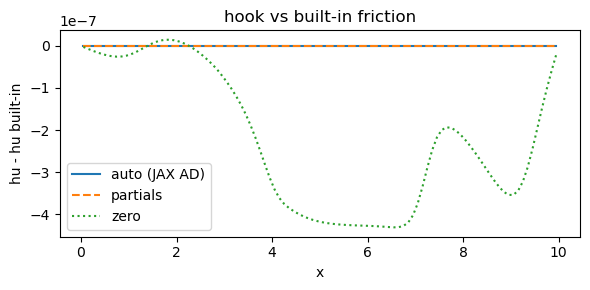

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
for (label, Qh), style in zip(Q.items(), ("-", "--", ":")):
    ax.plot(x, Qh[2] - Q_builtin[2], style, label=label)
ax.set(xlabel="x", ylabel="hu - hu built-in", title="hook vs built-in friction")
ax.legend()
fig.tight_layout()

In [7]:
assert np.abs(Q["auto (JAX AD)"] - Q_builtin).max() <= 1e-13
assert np.abs(Q["partials"] - Q_builtin).max() <= 1e-13
assert 1e-9 < np.abs(Q["zero"] - Q_builtin).max() < 1e-5